# 01 — Exploratory data analysis

**Rule:** EDA looks at the training and validation periods only (up to end of 2022). The test period (2023 onward) stays unseen until the final evaluation, so nothing we notice here can be tuned to it.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from spysignal import data, features, labels, splits
from spysignal.features import FEATURES

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 1.5,
})
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#a3a29d"
CLASS_COLORS = {"Sell": "#e34948", "Hold": GRAY, "Buy": BLUE}   # diverging: red - gray - blue
NAMES = {-1: "Sell", 0: "Hold", 1: "Buy"}

In [2]:
# data/raw.csv is created once with data.download(); everyone uses the same file.
if not data.RAW_FILE.exists():
    data.download()
df = data.load()

X_all = features.build_features(df)
fwd = labels.forward_return(df)
scale = labels.threshold_scale(df)
usable = X_all[list(FEATURES)].notna().all(axis=1) & fwd.notna() & scale.notna()
masks = splits.split_masks(df.index, usable)

k = labels.fit_k(fwd[masks["train"]], scale[masks["train"]])   # fitted on TRAIN only
y = labels.make_labels(fwd, scale, k)
print(f"k = {k:.3f}  (Buy if 5-day return > {k:.2f} x expected 5-day volatility)")
for name, m in masks.items():
    print(f"{name:5s}: {m.sum():5d} rows  {df.index[m].min().date()} -> {df.index[m].max().date()}")

k = 0.379  (Buy if 5-day return > 0.38 x expected 5-day volatility)
train:  3636 rows  2006-07-17 -> 2020-12-22
val  :   497 rows  2021-01-04 -> 2022-12-21
test :   940 rows  2023-01-03 -> 2026-10-01


In [3]:
dev = masks["train"] | masks["val"]
train = masks["train"]

## 1. SPY over the development period
Log scale, so equal vertical distances are equal percentage moves.

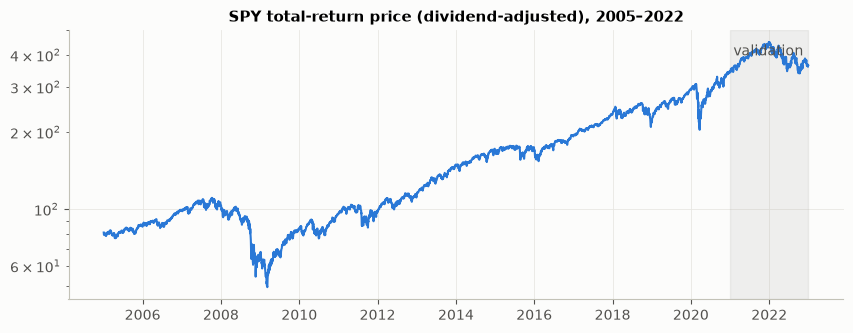

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.5))
px = df.loc[:"2022-12-31", "close"]
ax.plot(px.index, px, color=BLUE)
ax.set_yscale("log")
ax.axvspan(pd.Timestamp("2021-01-01"), pd.Timestamp("2022-12-31"), color=GRAY, alpha=0.15)
ax.text(pd.Timestamp("2021-02-01"), px.max() * 0.98, "validation", va="top", color="#52514e")
ax.set_title("SPY total-return price (dividend-adjusted), 2005–2022")
plt.show()

## 2. Target classes
Labels are volatility-scaled: *Buy* means the next 5 days rose by more than k × the expected 5-day move given recent volatility. k is set on the training period so a third of labels are Hold.

,train,val
label,,
Sell,25.0%,32.0%
Hold,33.3%,28.6%
Buy,41.6%,39.4%


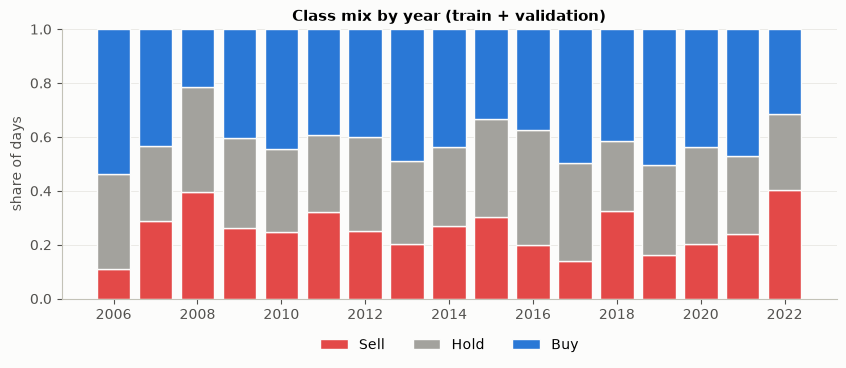

In [5]:
shares = pd.DataFrame({
    s: y[masks[s]].map(NAMES).value_counts(normalize=True) for s in ["train", "val"]
}).loc[["Sell", "Hold", "Buy"]]
display(shares.style.format("{:.1%}"))

by_year = (y[dev].map(NAMES).groupby(y[dev].index.year).value_counts(normalize=True)
           .unstack()[["Sell", "Hold", "Buy"]])
fig, ax = plt.subplots(figsize=(10, 3.5))
bottom = np.zeros(len(by_year))
for c in by_year.columns:
    ax.bar(by_year.index, by_year[c], bottom=bottom, color=CLASS_COLORS[c], label=c,
           edgecolor="#fcfcfb", linewidth=1)
    bottom += by_year[c].to_numpy()
ax.set_ylim(0, 1); ax.set_ylabel("share of days"); ax.set_xticks(by_year.index[::2])
ax.set_title("Class mix by year (train + validation)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.show()

Buy outnumbers Sell because the market drifts upward. This is the class imbalance the assignment asks us to handle; we use class weights in the models.

## 3. Feature distributions (training period)

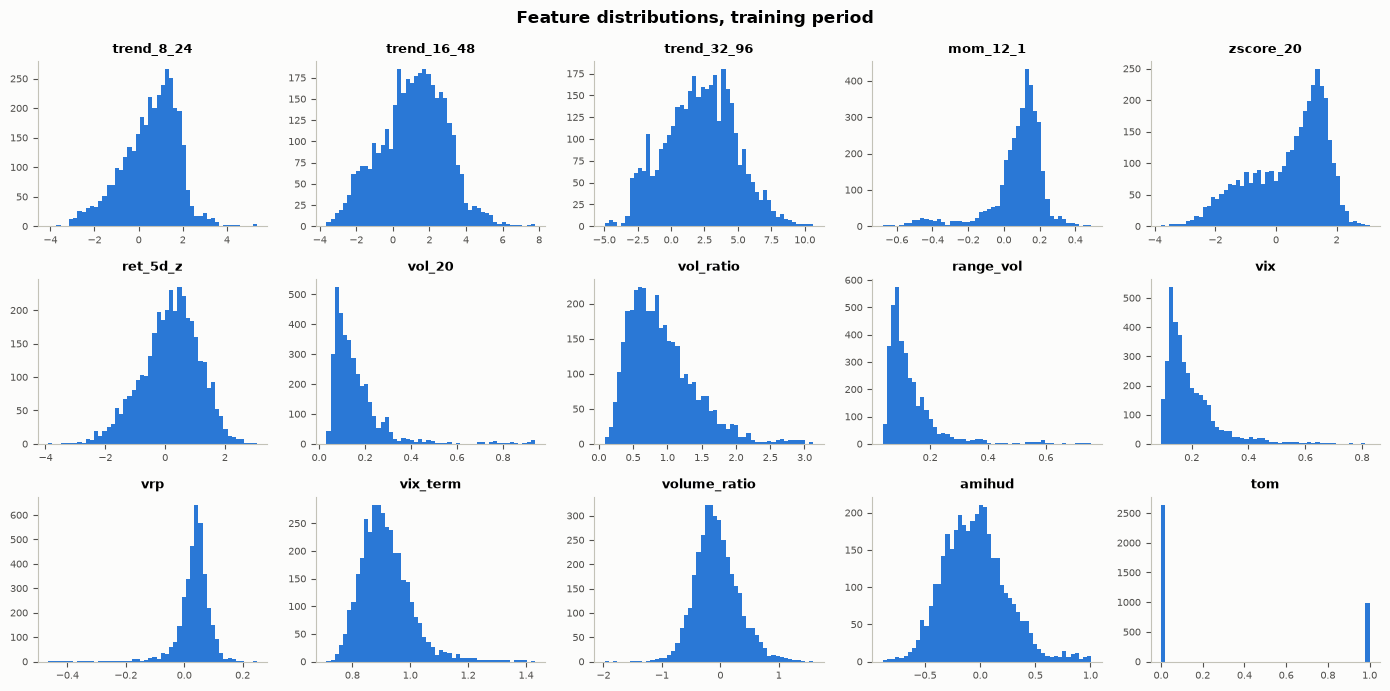

,mean,std,min,max
trend_8_24,0.544,1.266,-4.100,5.355
trend_16_48,1.135,1.806,-3.638,7.775
trend_32_96,2.172,2.650,-4.976,10.633
mom_12_1,0.077,0.157,-0.679,0.491
zscore_20,0.408,1.258,-3.794,3.089
ret_5d_z,0.178,0.963,-3.911,3.067
vol_20,0.163,0.125,0.032,0.940
vol_ratio,0.919,0.482,0.084,3.126
range_vol,0.134,0.094,0.036,0.758
vix,0.197,0.097,0.091,0.827


In [6]:
cols = list(FEATURES)
fig, axes = plt.subplots(3, 5, figsize=(14, 7))
for ax, c in zip(axes.flat, cols):
    ax.hist(X_all.loc[train, c], bins=50, color=BLUE)
    ax.set_title(c, fontsize=9); ax.tick_params(labelsize=7); ax.grid(False)
fig.suptitle("Feature distributions, training period", fontweight="bold")
fig.tight_layout(); plt.show()

display(X_all.loc[train, cols].describe().T[["mean", "std", "min", "max"]].round(3))

## 4. How correlated are the features?
Strongly correlated features carry the same information. That matters for logistic regression (unstable coefficients) and for interpreting feature importance.

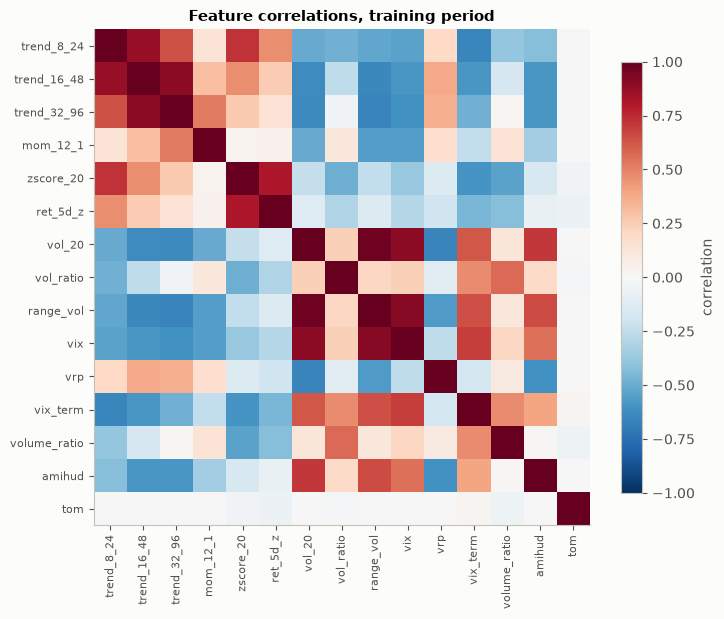

Pairs with |correlation| > 0.8:
vol_20       range_vol      0.97
range_vol    vix            0.91
trend_16_48  trend_32_96    0.90
vol_20       vix            0.90
trend_8_24   trend_16_48    0.87
zscore_20    ret_5d_z       0.81


In [7]:
corr = X_all.loc[train, cols].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(cols)), cols, fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="correlation")
ax.set_title("Feature correlations, training period")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print("Pairs with |correlation| > 0.8:")
print(pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False).round(2).to_string())

## 5. Does VWAP add anything over a plain moving average?
Real VWAP needs intraday trades; with daily bars we approximate a 20-day VWAP from typical price (H+L+C)/3 weighted by volume. If it moves almost one-for-one with price ÷ 20-day average, it adds nothing and stays out of the model.

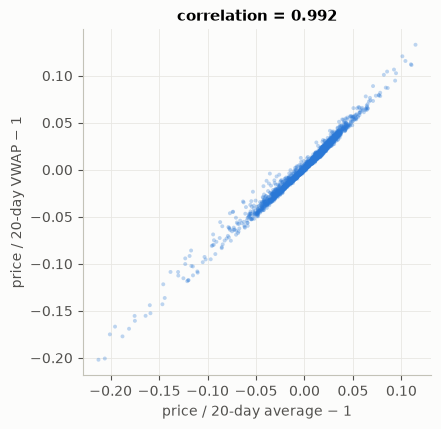

In [8]:
a, b = X_all.loc[train, "px_sma20"], X_all.loc[train, "px_vwap20"]
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(a, b, s=8, alpha=0.3, color=BLUE, edgecolors="none")
ax.set_xlabel("price / 20-day average − 1"); ax.set_ylabel("price / 20-day VWAP − 1")
ax.set_title(f"correlation = {a.corr(b):.3f}")
plt.show()

## 6. Does any single feature relate to the future return? (training period)
Spearman rank correlation between each feature and the next 5-day return in volatility units. Expect tiny numbers (|ρ| < 0.05 is normal for markets). This is a sanity check, not feature selection.

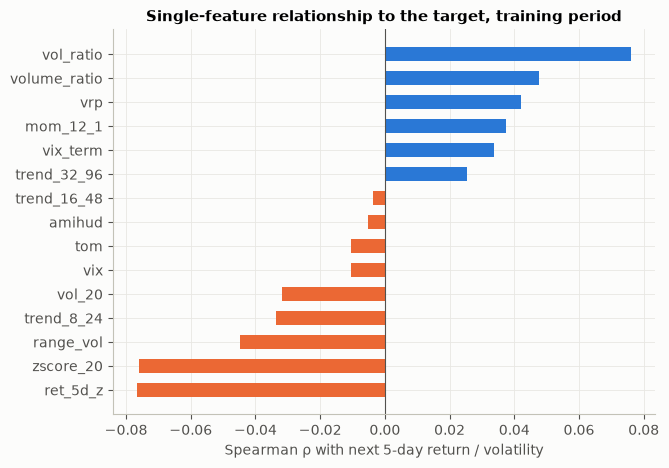

In [9]:
z = (fwd / scale)[train]
rho = X_all.loc[train, cols].corrwith(z, method="spearman").sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(rho.index, rho, color=[BLUE if v > 0 else ORANGE for v in rho], height=0.6)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_xlabel("Spearman ρ with next 5-day return / volatility")
ax.set_title("Single-feature relationship to the target, training period")
plt.show()

## Notes for the group
Fill in after reading the outputs:
- Which features are near-duplicates (section 4)? Keep one of each pair for the logistic model.
- Does the class mix shift between calm and crisis years (section 2)?
- Which single features show any relationship at all (section 6), and does the sign make economic sense (trend positive? reversal negative?)